# Module 05 (part 2): Checking the snow pillow with a shovel

*The code behind GEOS 212: Water in the West, Boise State University*

A SNOTEL station measures snow water equivalent (SWE) automatically with a **snow pillow**: a large, flat bladder of antifreeze under the snow. As snow piles up, its weight squeezes the pillow, and a pressure sensor turns that into SWE every day. But how do we know the pillow is right?

The old-fashioned way: dig a **snow pit**. Cut out a known volume of snow from each layer, weigh it to get its density, and add up density × thickness for every layer. That's exactly the snow-core math from the Module 05 lecture.

In the winters of 2020 and 2021, NASA's **SnowEx** field campaign dug snow pits about once a week at sites across the Boise River basin, including one right next to the Banner Summit SNOTEL pillow. Let's see how the shovel and the pillow compare.

**Where are we in the water year?** In the *snowpack*.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests

# The GEOS 212 "water" colors, so these plots match the lecture slides
INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

# If a live download fails (no internet, or an agency changes its website),
# we fall back to a copy of the data saved in this repository.
DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def fetch_text(url, cache_name):
    """Download text from `url`. Save a copy as data/<cache_name>.
    If the download fails, use the saved copy instead."""
    try:
        r = requests.get(url, timeout=60)
        r.raise_for_status()
        text = r.text
        if DATA_DIR.exists():
            (DATA_DIR / cache_name).write_text(text)
        print(f"Downloaded live data -> {cache_name}")
    except Exception as err:
        print(f"Live download failed ({type(err).__name__}); using saved copy of {cache_name}")
        local = DATA_DIR / cache_name
        text = local.read_text() if local.exists() else requests.get(DATA_URL + cache_name, timeout=60).text
    return text

In [2]:
def water_year(dates):
    """Water year: Oct 1 2025 - Sep 30 2026 is water year 2026."""
    return dates.year + (dates.month >= 10)

def wy_axis_date(dates):
    """Map every date onto one shared 'generic' water year (Oct 2000 - Sep 2001),
    so different years can be drawn on the same x-axis."""
    return pd.to_datetime([pd.Timestamp(2000 if d.month >= 10 else 2001, d.month, min(d.day, 28) if d.month == 2 else d.day)
                           for d in dates])

def month_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

In [3]:
def get_snotel_swe(site, state, start, end):
    """Daily SNOTEL snow water equivalent (inches) from the NRCS Report Generator."""
    url = ("https://wcc.sc.egov.usda.gov/reportGenerator/view_csv/customSingleStationReport/daily/"
           f"{site}:{state}:SNTL%7Cid=%22%22%7Cname/{start},{end}/WTEQ::value")
    text = fetch_text(url, f"snotel_{site}_{start}_{end}_WTEQ-value.csv")
    df = pd.read_csv(io.StringIO(text), comment="#", parse_dates=["Date"], index_col="Date")
    return df.iloc[:, 0].rename("swe_in")

## 2. The data

**SnowEx pits.** NASA's snow pit files (from the National Snow and Ice Data Center) need a free Earthdata login, so we saved a summary table with one row per pit: the site, time, location, total depth, total SWE (mm) and bulk density (kg/m³), calculated from each pit's layer-by-layer density measurements.

**SNOTEL.** Banner Summit (site 312) daily SWE, downloaded live from NRCS.

In [4]:
name = "snowex_boise_pits.csv"
source = DATA_DIR / name if (DATA_DIR / name).exists() else DATA_URL + name
pits = pd.read_csv(source, parse_dates=["time"])
print(f"{len(pits)} snow pits, {pits.time.min():%b %Y} to {pits.time.max():%b %Y}")
pits.site.value_counts()

119 snow pits, Dec 2019 to Apr 2021


site
Banner Snotel              23
Bogus Lower                18
Bogus Lower Trees          13
Lower Deer Point - Open    12
Banner Open                11
Bogus Upper                11
Lower Deer Point - Tree    10
LDP Tree                    7
LDP Open                    7
Mores Creek Summit          5
Banner Knob                 1
Mores Mountain              1
Name: count, dtype: int64

In [5]:
pillow = get_snotel_swe(312, "ID", "2019-10-01", "2021-09-30")

banner = pits[pits.site == "Banner Snotel"].copy()
# SNOTEL reports SWE at the start of each day; match each pit to its date and convert inches to mm
banner["pillow_mm"] = [pillow.get(t.normalize(), np.nan) * 25.4 for t in banner.time]
banner["diff_pct"] = 100 * (banner.swe_mm / banner.pillow_mm - 1)
banner[["time", "depth_cm", "swe_mm", "pillow_mm", "diff_pct"]].round(0).head(8)

Downloaded live data -> snotel_312_2019-10-01_2021-09-30_WTEQ-value.csv


/tmp/ipykernel_458/1367714788.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  banner[["time", "depth_cm", "swe_mm", "pillow_mm", "diff_pct"]].round(0).head(8)


,time,depth_cm,swe_mm,pillow_mm,diff_pct
0,2019-12-18 10:00:00,47.0,96.0,127.0,-25.0
4,2020-01-09 10:30:00,94.0,174.0,208.0,-16.0
9,2020-01-23 11:00:00,115.0,281.0,312.0,-10.0
12,2020-01-30 12:00:00,131.0,312.0,356.0,-12.0
17,2020-02-06 12:00:00,135.0,351.0,371.0,-5.0
23,2020-02-13 11:30:00,134.0,376.0,401.0,-6.0
26,2020-02-19 10:45:00,140.0,397.0,417.0,-5.0
34,2020-02-27 10:30:00,133.0,403.0,422.0,-4.0


## 3. Pit vs. pillow through two winters

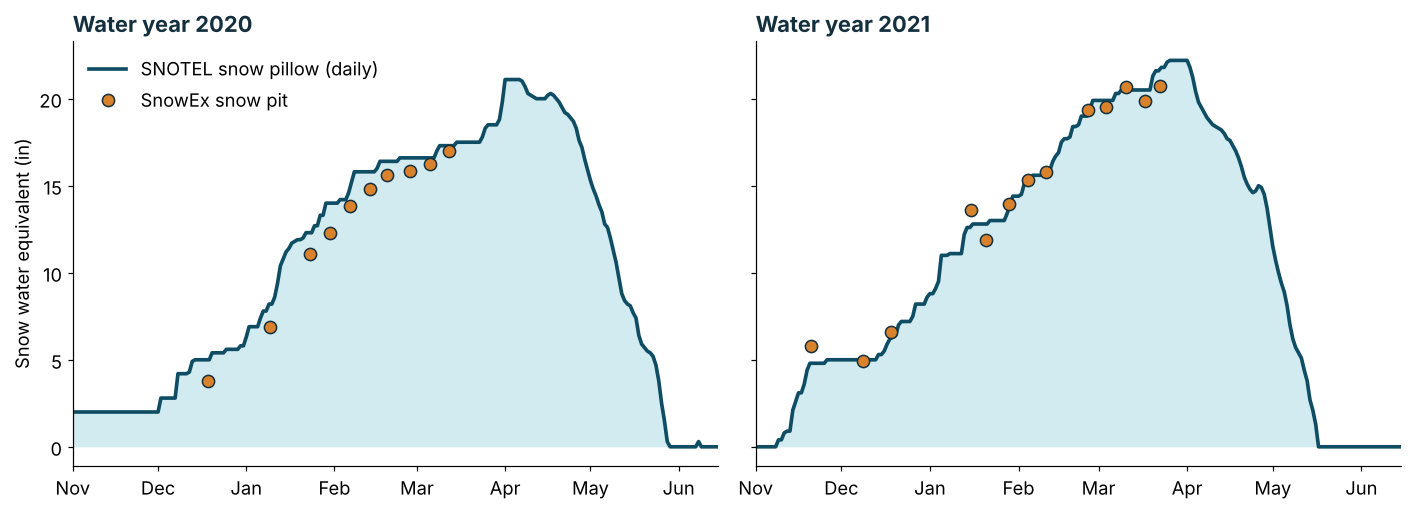

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, wy in zip(axs, [2020, 2021]):
    p = pillow[f"{wy-1}-10-01":f"{wy}-06-30"]
    ax.fill_between(p.index, 0, p, color=GLACIER, alpha=0.25, lw=0)
    ax.plot(p.index, p, color=DEEP, lw=2.4, label="SNOTEL snow pillow (daily)")
    q = banner[banner.time.between(f"{wy-1}-10-01", f"{wy}-07-01")]
    ax.plot(q.time, q.swe_mm / 25.4, "o", ms=8, mfc=OCHRE, mec=INK, label="SnowEx snow pit")
    ax.set_xlim(pd.Timestamp(f"{wy-1}-11-01"), pd.Timestamp(f"{wy}-06-15"))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.set_title(f"Water year {wy}", loc="left", fontweight="bold", color=INK)
axs[0].set_ylabel("Snow water equivalent (in)")
axs[0].legend(frameon=False, loc="upper left")
plt.tight_layout()

Let's put a number on the agreement. We'll use the **median** difference (is the pit usually higher or lower?), the **mean absolute** difference (how big is a typical miss, ignoring the sign?), and the **correlation** $r$ (do they rise and fall together?).

In [7]:
ok = banner.dropna(subset=["pillow_mm"])
print(f"{len(ok)} pits with a same-day pillow value")
print(f"Median difference (pit vs pillow): {ok.diff_pct.median():+.0f}%")
print(f"Mean absolute difference:          {ok.diff_pct.abs().mean():.0f}%")
print(f"Correlation r:                     {np.corrcoef(ok.swe_mm, ok.pillow_mm)[0, 1]:.2f}")
worst = ok.loc[ok.diff_pct.abs().idxmax()]
print(f"Biggest miss: {worst.time:%b %d, %Y}, pit {worst.swe_mm:.0f} mm vs pillow {worst.pillow_mm:.0f} mm ({worst.diff_pct:+.0f}%)")

23 pits with a same-day pillow value
Median difference (pit vs pillow): -2%
Mean absolute difference:          7%
Correlation r:                     0.99
Biggest miss: Dec 18, 2019, pit 96 mm vs pillow 127 mm (-25%)


A shovel and a pressure sensor, a few meters apart, agree to within about 7% on average, and they rise and fall almost perfectly together. The biggest misses come early in the season, when the snow is thin and patchy, so a few meters can make a real difference.

## 4. The snowpack gets denser all winter

Bulk density is the average density of the whole pit: total SWE divided by total depth (times the density of water). Let's watch it change through each winter at Banner, and compare with the other SnowEx sites.

Banner WY2020: first pit 204 kg/m³, last pit 324 kg/m³
Banner WY2021: first pit 192 kg/m³, last pit 314 kg/m³


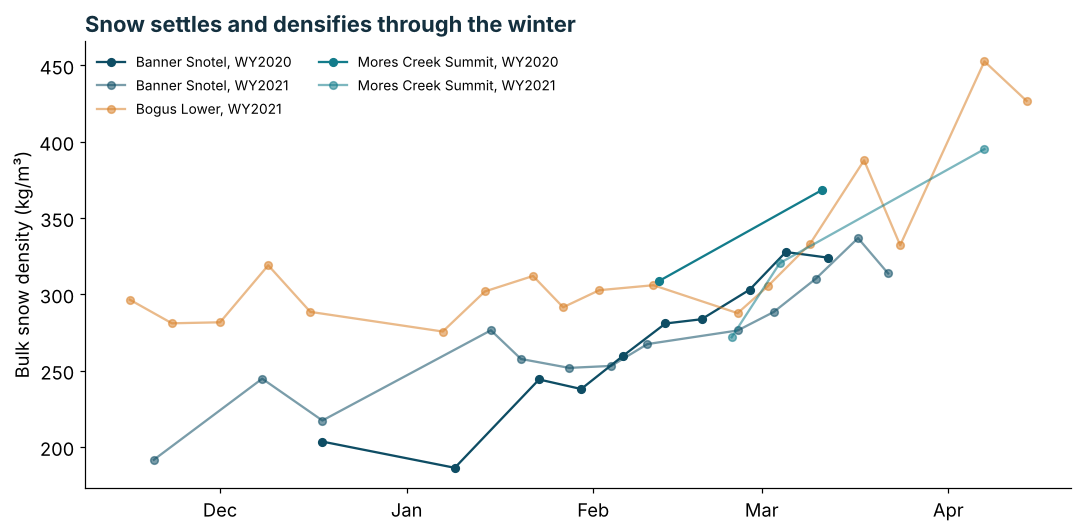

In [8]:
pits["wy"] = pits.time.dt.year + (pits.time.dt.month >= 10)
fig, ax = plt.subplots(figsize=(10, 5))
for site, color in [("Banner Snotel", DEEP), ("Bogus Lower", OCHRE), ("Mores Creek Summit", RIVER)]:
    for wy in [2020, 2021]:
        d = pits[(pits.site == site) & (pits.wy == wy)]
        if d.empty:
            continue                      # no pits at this site that winter
        x = wy_axis_date(d.time)
        ax.plot(x, d.bulk_density, "o-", color=color, ms=5, lw=1.5, alpha=1 if wy == 2020 else 0.55,
                label=f"{site}, WY{wy}")
month_axis(ax)
ax.set_ylabel("Bulk snow density (kg/m³)")
ax.legend(frameon=False, fontsize=9, ncol=2)
ax.set_title("Snow settles and densifies through the winter", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

for wy in [2020, 2021]:
    d = banner[banner.time.dt.year + (banner.time.dt.month >= 10) == wy]
    print(f"Banner WY{wy}: first pit {d.bulk_density.iloc[0]:.0f} kg/m³, last pit {d.bulk_density.iloc[-1]:.0f} kg/m³")

New snow keeps landing on top, but the weight of the pack and melt-freeze cycles compact everything underneath. That's the same densification you saw in the SNOTEL depth and SWE data in the [first Module 05 notebook](05_snow_to_streamflow_forecast.ipynb).

## 5. Your turn

1. **Open vs. trees.** Compare SWE at "Bogus Lower" with "Bogus Lower Trees" (and "Lower Deer Point - Open" with "Lower Deer Point - Tree") on dates when both were dug. How much snow does the forest canopy intercept?
2. **Elevation.** Make a scatter plot of SWE vs. date for every site, colored by site. Which sites have the most snow, and why? (Look up their elevations.)
3. **Why still dig pits?** If the pillow and pits agree this well, why do agencies still send people out with shovels? List at least three things a pit tells you that a pillow can't.

### Why code?
Each SnowEx pit file holds dozens of layer measurements. Code turns 119 pit files into one tidy table, matches each pit to the right day of SNOTEL data, and reports the agreement in a few lines.

---
*Data: NASA SnowEx20 Time Series Snow Pit Measurements V002 (SNEX20_TS_SP, doi:10.5067/KZ43HVLZV6G4) and SnowEx21 Time Series Snow Pits V001 (SNEX21_TS_SP, doi:10.5067/QIANJYJGRWOV), NSIDC DAAC; pit SWE from gap-filled density profiles. NRCS SNOTEL Banner Summit (312).*